# Isolation Forest Sensitivity and Feature Ablation Analysis

In preparation of the model evaluations, the following set up includes required models from python libraries and creating unlabeled training data.

In [1]:
# TASK 3 PART TWO ---------------------------------------

#import IsolationForest
from sklearn.ensemble import IsolationForest
from IPython.display import display
import time
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Label Data Files
train_transaction = pd.read_csv("Data/train_transaction.csv")
train_identity = pd.read_csv("Data/train_identity.csv")

# Merging two databse by identity id by creating a new dataframe
df = train_transaction.merge(train_identity, on="TransactionID", how="left")

# Database used for learning
# + only uses col that have numbers (don't want categorical)
# fill in empty cells
newdf = df[train_transaction.columns].drop(columns="isFraud").select_dtypes(include="number").fillna(-999)

# Results table for every experiment in Part 2 (one row per experiment)
all_results = pd.DataFrame(columns=["ROC-AUC", "PR-AUC", "Processing Time (s)"], dtype=float)



### 2.1 E0 Baseline Model
The isolationforest baseline model was fitting without manipulating any parameters. In order to evaluate the performance, ROC AUC score is calculated and the top 10 anomalous transactions is pulled.

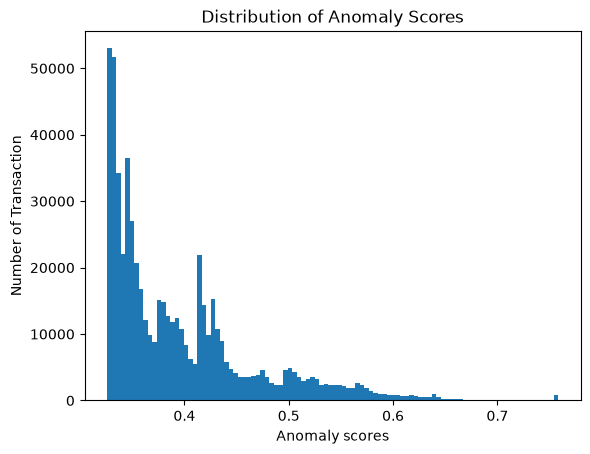

,TransactionAmt,ProductCD,card4,card6,anomaly_score,isFraud
560471,110.0,S,mastercard,credit,0.758096,0
559747,110.0,S,mastercard,credit,0.758096,0
559746,110.0,S,mastercard,credit,0.758096,0
561451,106.0,S,mastercard,credit,0.758096,0
560473,110.0,S,mastercard,credit,0.758096,0
559938,110.0,S,mastercard,credit,0.758096,0
559766,110.0,S,mastercard,credit,0.758096,0
559742,110.0,S,mastercard,credit,0.758096,0
559613,106.0,S,mastercard,credit,0.758096,0
559739,110.0,S,mastercard,credit,0.758096,0


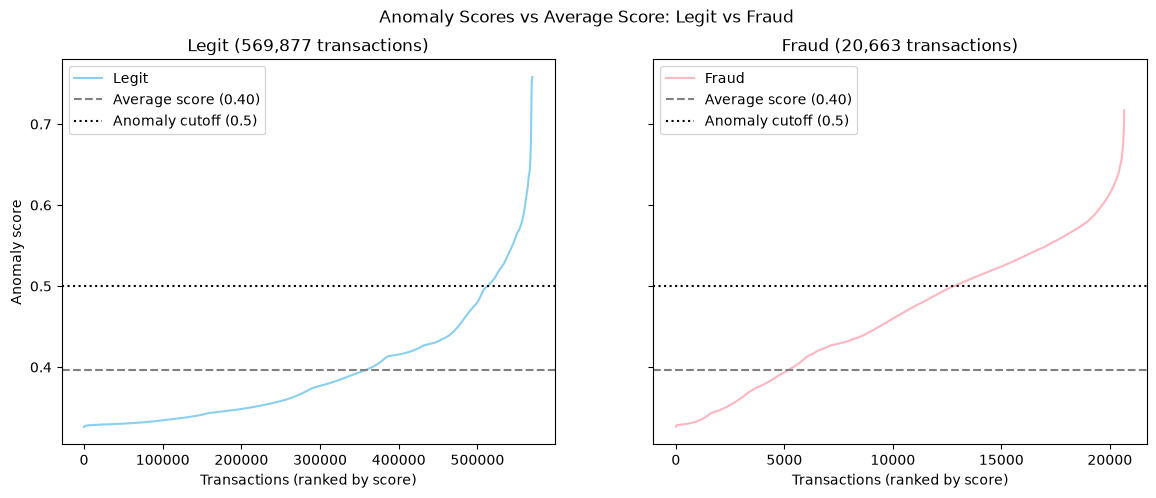

E0 Baseline ROC-AUC: 0.751


In [18]:
# E0: Baseline Isolation Forest (Default Parameters)
start = time.perf_counter() #start of process time tracker
isolated = IsolationForest(random_state=100)
isolated.fit(newdf)
e0_scores = -isolated.score_samples(newdf)
end = time.perf_counter() #end of process time tracker

# save E0 results to the results table
all_results.loc["E0: Baseline"] = [roc_auc_score(df["isFraud"], e0_scores),
                                   average_precision_score(df["isFraud"], e0_scores),
                                   end - start]

# copy of the original df so the anomaly score doesn't get added to df
tempdf = df.copy()

# Create a new col in tempdf that stores all of the anomaly score 
tempdf["anomaly_score"] = -isolated.score_samples(newdf)

# Finding top 10 most anomalous transactions 
top10 = tempdf.sort_values("anomaly_score", ascending=False).head(10)

#finding the dirstribution of the anomaly scores
# higher anomaly score = isolated in few splits = unusual
# anomaly score = 0.5 = average number of splits
tempdf["anomaly_score"].plot(kind="hist", bins=100, 
                     title = "Distribution of Anomaly Scores",
                     xlabel = "Anomaly scores",
                     ylabel = "Number of Transaction")
plt.show()

display(top10[["TransactionAmt", "ProductCD", "card4", "card6", "anomaly_score", "isFraud"]])



# Scatter: how far the anomalous transactions (score > 0.5) are from the average score
mean_score = tempdf["anomaly_score"].mean()
anomalous = tempdf.sort_values("anomaly_score").reset_index(drop=True)
anom_legit = anomalous[anomalous["isFraud"] == 0]
anom_fraud = anomalous[anomalous["isFraud"] == 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# rank each group on its own (0 = lowest score) so each line spans its full chart
axes[0].plot(range(len(anom_legit)), anom_legit["anomaly_score"], color="#89CFF0", label="Legit")
axes[0].set_title(f"Legit ({len(anom_legit):,} transactions)")
axes[1].plot(range(len(anom_fraud)), anom_fraud["anomaly_score"], color="#FFB6C1", label="Fraud")
axes[1].set_title(f"Fraud ({len(anom_fraud):,} transactions)")

for ax in axes:
    ax.axhline(mean_score, color="grey", linestyle="--", label=f"Average score ({mean_score:.2f})")
    ax.axhline(0.5, color="black", linestyle=":", label="Anomaly cutoff (0.5)")
    ax.set_xlabel("Transactions (ranked by score)")
    ax.legend()
axes[0].set_ylabel("Anomaly score")

fig.suptitle("Anomaly Scores vs Average Score: Legit vs Fraud")
plt.show()
# ROC-AUC of the baseline model (uses all transactions, not just the anomalous ones)
e0_roc_auc = roc_auc_score(tempdf["isFraud"], tempdf["anomaly_score"])
print(f"E0 Baseline ROC-AUC: {e0_roc_auc:.3f}")

Evaluating the first distribution diagram, the following observation was observed
- All scores were between 0.33 - 0.76
- The distribution seem to be positively skewed with most transactions sitting at the lower end (at 0.33-0.45)
- There are small bumps at around 0.33, 0.35 and 0.42
- Given that below 0.5 is normal transactions; small proportion of the transaction are considered anomaly (due to long right tail)

Furthermore, the 10 most anomalous transactions pulled from baseline model are nearly identical in transaction amount (110), productCD(S) and card type (mastercard, credit) with an anomaly score of 0.758096. 
The transaction amount seems to be normal as it sits right between the mean of 135.03 and median 68.77. 
By analyzing their row number, they seem to very close together, suggesting that the payment happened around the same time. **Therefore, it seems like the model isolated one rare cluster of similar transactions**. 


### 2.2 E1 Sensitivity to Contamination Parameter
Contamination values of [0.01, 0.02, 0.035, 0.05, 0.1] will be tested

contamination,0.010,0.020,0.035,0.050,0.100
Transactions Flagged,5906.000,11810.000,20669.000,29513.000,59054.000
ROC-AUC,0.751,0.751,0.751,0.751,0.751
PR-AUC,0.094,0.094,0.094,0.094,0.094
Processing Time (s),18.676,13.231,12.588,12.552,12.371


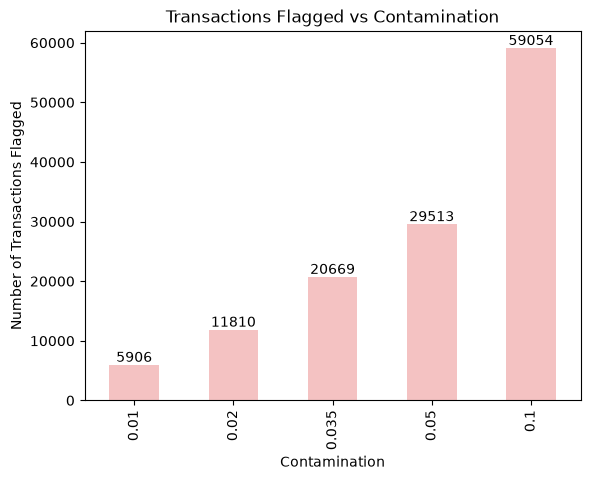

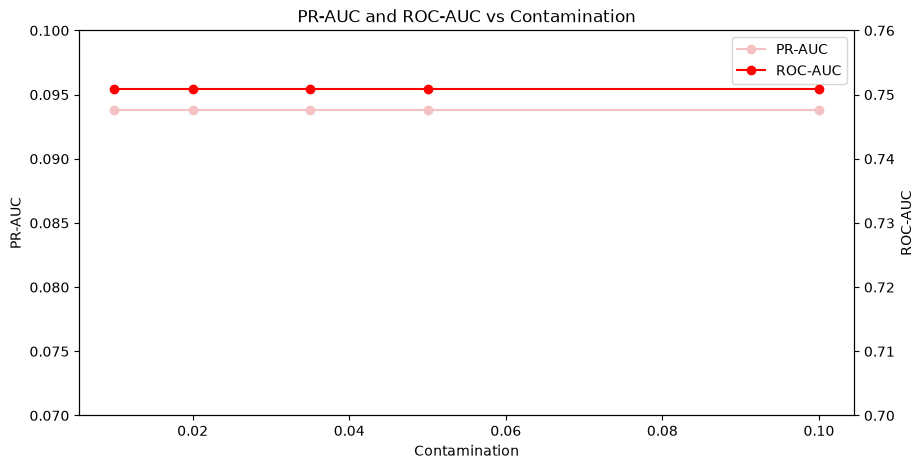

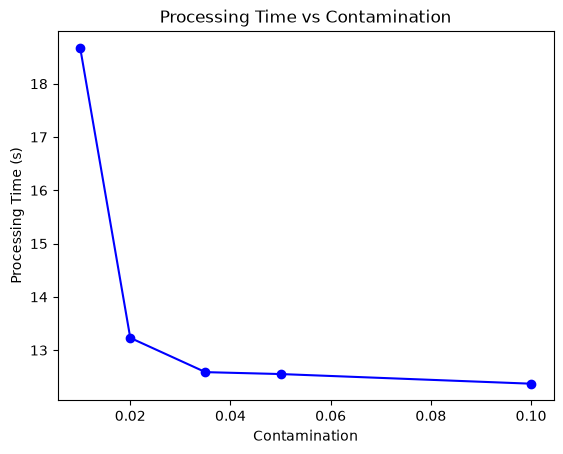

In [ ]:
# E1: Sensitivity to Contamination

#Contamination Values that will be tested
contaminationval = [0.01, 0.02, 0.035, 0.05, 0.1]

# empty table: one column for each contamination value
# rows for Transactions Flaaged, ROC-AUC, PR-AUC and Process time
cont_df = pd.DataFrame(index=["Transactions Flagged", "ROC-AUC", "PR-AUC", "Processing Time (s)"],
                       columns=contaminationval, dtype=float)
cont_df.columns.name = "contamination"

# loop to run the fitted model
i = 0
while i < len(contaminationval): # let i be the index of the experiment values
    j = contaminationval[i]

    # fit the model + score every transaction, timing both
    start = time.perf_counter() # start of process time tracker
    model = IsolationForest(contamination=j, random_state=100)
    model.fit(newdf)
    scores = -model.score_samples(newdf) # calculate the anomaly score
    end = time.perf_counter() # end of process time tracker

    # predict() produces the following 
    #  -1 = anomaly (flagged as fraud)
    #   1 = normal
    flagged = (model.predict(newdf) == -1).sum() # number of flagged transactions

    # add the results to the table (cont_df)
    cont_df.loc["Transactions Flagged", j] = flagged
    cont_df.loc["ROC-AUC", j] = roc_auc_score(df["isFraud"], scores)
    cont_df.loc["PR-AUC", j] = average_precision_score(df["isFraud"], scores)
    cont_df.loc["Processing Time (s)", j] = end - start

    i += 1

display(cont_df.round(3))

# Bar chart: number of transactions flagged for each contamination value
flag_bar = cont_df.loc["Transactions Flagged"].plot(kind="bar", color="#F4C2C2",  # baby pink
                                                    title="Transactions Flagged vs Contamination",
                                                    xlabel="Contamination",
                                                    ylabel="Number of Transactions Flagged")
flag_bar.bar_label(flag_bar.containers[0], fmt="%d")
plt.show()

# Line chart 1: PR-AUC on the left axis, ROC-AUC on the right axis
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(contaminationval, cont_df.loc["PR-AUC"], marker="o", color="#F4C2C2", label="PR-AUC")
ax1.set_xlabel("Contamination")
ax1.set_ylabel("PR-AUC")
ax1.set_ylim(0.07, 0.1)

ax2 = ax1.twinx() # second y axis that shares the same x axis
ax2.plot(contaminationval, cont_df.loc["ROC-AUC"], marker="o", color="red", label="ROC-AUC")
ax2.set_ylabel("ROC-AUC")
ax2.set_ylim(0.7, 0.8)

# combine the legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

ax1.set_title("PR-AUC and ROC-AUC vs Contamination")
plt.show()

# Line chart 2: processing time on its own
cont_df.loc["Processing Time (s)"].plot(kind="line", marker="o", color="blue",
                                        title="Processing Time vs Contamination",
                                        xlabel="Contamination",
                                        ylabel="Processing Time (s)")
plt.show()

From the produced diagram the following findings were pulled:

1. Bar graph: Transaction Flagged vs contamination parameter values
The bar graph demonstrates a growing trend in number flagged proportional to the increase in contamination parameter value. Calculating rate of change between each increase of contamination magnitude, it appears to be a linear relationship (rate of change in flagged transaction per +0.01 contamination = 5,904, 5,906, 5,896, 5,908) Evaluating contamination parameter = 0.035, the flagged transaction quantity of 20,669 is the closest to actual fraud transaction amount (20,663).
**Therefore, contamination works purely as a cut-off dial and contamination parameter has a linear relationship with the flagged transaction. It decides how many transactions get flagged (exactly that share of the data)**. 

2. PR-AUC and ROC-AUC vs contamination parameter values
For all contamination value the PR-AUC and ROC-AUC remain stable at 0.094 and 0.751 respectively. **Therefore, the change inn contamination parameter does not have impact on PR-AUC and ROC-AUC.**

3. Process Time vs Contamination parameter values
The model runtime ranged from about 14 to 19 seconds where the first run (contamination = 0.01) was the slowest (19 s), and the rest were similar (14–15 s).
**Therefore, there was no obvious clear pattern: higher contamination doesn’t drastically make the model faster or slower**.

### 2.3 E2 Sensitivity to n_estimators Parameter
n_estimators values of [10, 25, 50, 75, 100, 150, 200, 300, 500, 1000] will be tested

n_estimators,10,25,50,75,100,150,200,300,500,1000
ROC-AUC,0.759,0.762,0.755,0.752,0.751,0.754,0.752,0.752,0.753,0.752
PR-AUC,0.095,0.104,0.096,0.094,0.094,0.097,0.096,0.097,0.097,0.097


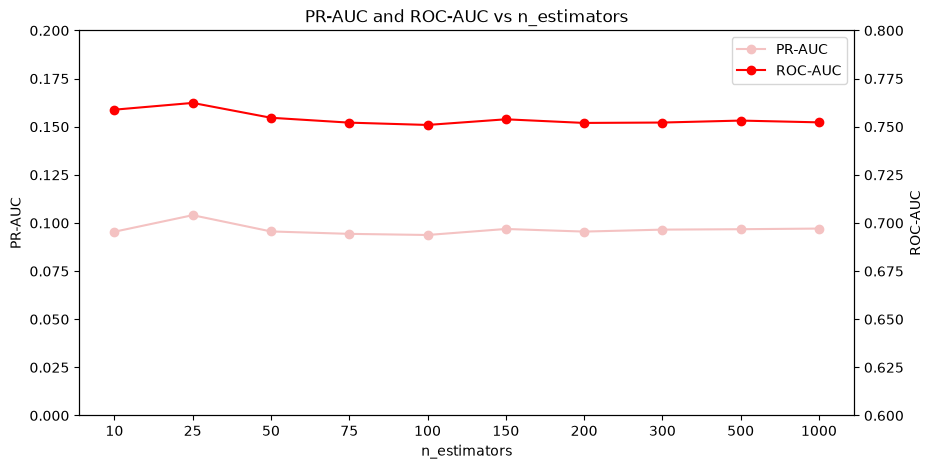

,10 vs 25,25 vs 50,50 vs 75,75 vs 100,100 vs 150,150 vs 200,200 vs 300,300 vs 500,500 vs 1000
Overlapping IDs,74.661,75.898,92.288,94.305,91.305,94.949,93.22,91.797,93.169


In [19]:
# E2: Sensitivity to Number of Trees (n_estimators)

#n_estimators Values that will be tested
n_estimator_values = [10, 25, 50, 75, 100, 150, 200, 300, 500, 1000]

# empty table: one column for each n_estimators value
# rows for ROC AUC and PR AUC
est_df = pd.DataFrame(index=["ROC-AUC", "PR-AUC"], columns=n_estimator_values, dtype=float)
est_df.columns.name = "n_estimators"

# Dictionary that contrains one dataframe per n_estimator value
# to store n_estimator's top 5,900 most anomalous transactions
# 1% of total transactions
top5900 = {}
for n in n_estimator_values:
    top5900[n] = pd.DataFrame(columns=["TransactionID", "anomaly_score"])

# for loop for fitting the isolation forest
i = 0
while i < len(n_estimator_values):
    j = n_estimator_values[i]

    # fit the model + score every transaction
    model = IsolationForest(n_estimators=j, random_state=100)
    model.fit(newdf)
    scores = -model.score_samples(newdf) # calculate the anomaly score

    # store the top 5,900 most anomalous transactions (id + anomaly score)
    scoredf = pd.DataFrame({"TransactionID": df["TransactionID"], "anomaly_score": scores})
    # find the top 5900 transacion with largest anomaly score
    top5900[j] = scoredf.nlargest(5900, "anomaly_score").reset_index(drop=True) 

    # add the results to the table
    est_df.loc["ROC-AUC", j] = roc_auc_score(df["isFraud"], scores)
    est_df.loc["PR-AUC", j] = average_precision_score(df["isFraud"], scores)

    i += 1

display(est_df.round(3))

# Line chart: PR-AUC on the left axis, ROC-AUC on the right axis
x_pos = range(len(n_estimator_values)) #setting x axis to not to scale for better graph reference

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(x_pos, est_df.loc["PR-AUC"], marker="o", color="#F4C2C2", label="PR-AUC")
ax1.set_xlabel("n_estimators")
ax1.set_ylabel("PR-AUC")
ax1.set_ylim(0, 0.2)

ax2 = ax1.twinx() # second y axis that shares the same x axis
ax2.plot(x_pos, est_df.loc["ROC-AUC"], marker="o", color="red", label="ROC-AUC")
ax2.set_ylabel("ROC-AUC")
ax2.set_ylim(0.6, 0.8)

# combine the legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

ax1.set_xticks(x_pos)
ax1.set_xticklabels(n_estimator_values) # show the n_estimators values under each point
ax1.set_title("PR-AUC and ROC-AUC vs n_estimators")
plt.show()


# Overlap of the top 5,900 transactions between neighbouring n_estimators values
est_compdf = pd.DataFrame(index=["Overlapping IDs"],
                          columns=["10 vs 25", "25 vs 50", "50 vs 75", "75 vs 100", "100 vs 150", 
                                   "150 vs 200", "200 vs 300", "300 vs 500", "500 vs 1000"], dtype=float)

i = 0
while i < 9:
    first = top5900[n_estimator_values[i]]
    second = top5900[n_estimator_values[i + 1]]

    # count how many TransactionIDs appear in both top 5,900 lists
    overlap = len(set(first["TransactionID"]) & set(second["TransactionID"]))

    # add the overlap to the table at column index i
    est_compdf.iloc[0, i] = round(overlap / 5900 * 100,3)

    i += 1

display(est_compdf)

From the produced diagram the following findings were pulled:

1. PR-AUC and ROC-AUC vs n_estimators
Only between few trees (10–50), AUC metrics move slightly more in comparison to others: ROC-AUC 0.759–0.762, PR-AUC 0.095–0.104 for tree 10 and 25 respectively (AUC metrics peak at 25 trees). From 75–100 trees onwards, both lines are relatively flat: ROC-AUC about 0.752, PR-AUC about 0.097.
**Since the total range is small (PR-AUC 0.094–0.104), therefore adding trees (increasing n_estimators parameter) doesn’t improve fraud detection. More trees will make results steadier but not better. The 25-tree peak is most likely random variation from having too few trees.**

2. Top-1% overlap between neighbouring settings
The table highlights the % of same anomalous transaction in top 5900 transactions between two estimated models. 
- 10 vs 25 and 25 vs 50: only about 75–76 overlap, so about a quarter of the top-flagged list changes. The ranking is unstable.
- However, from 50 vs 75 onwards: overlap jumps to 91–95% and remains stable in that range, all the way to 500 vs 1000 (93.2%).
**Therefore, the model is unstable at n_estimators below 25 and relatively stabilized above 50**

### 2.4 E3 Sensitivity to max_samples Parameter
max_samples values of [128, 256, 512, fullset] will be tested for 256 is the default

max_samples,128,512,"Full (590,540)"
Transactions Flagged,88364.000,44898.000,3710.000
ROC-AUC,0.752,0.751,0.714
PR-AUC,0.094,0.093,0.082
Processing Time (s),12.837,9.196,44.457


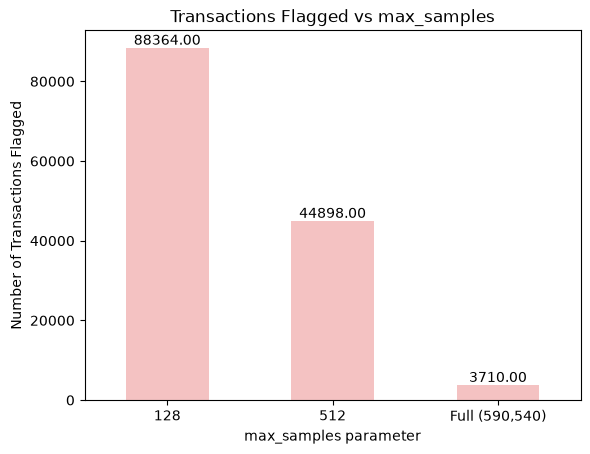

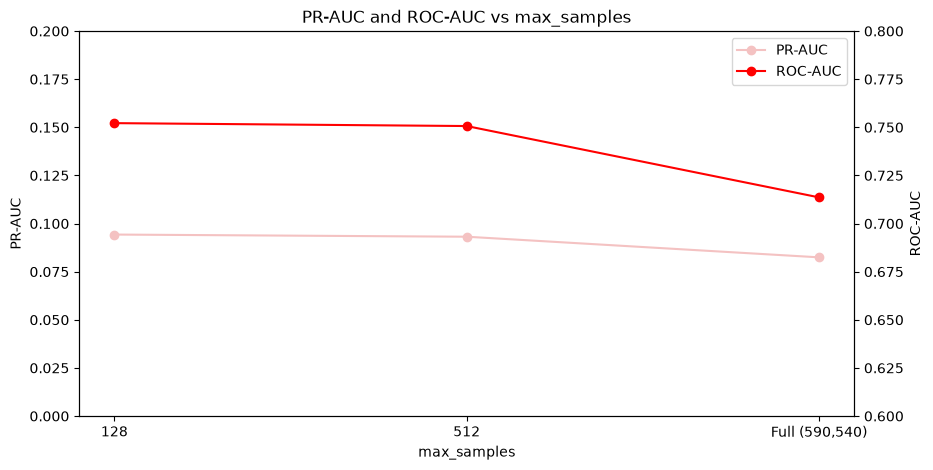

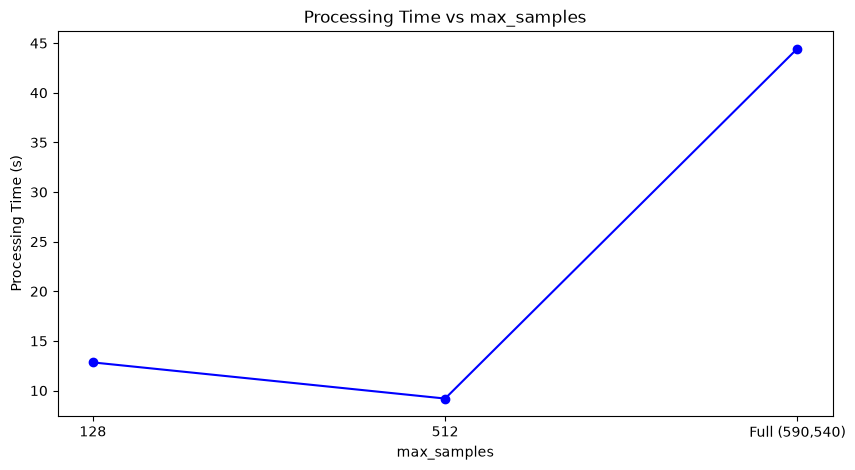

In [ ]:
# E3: Sensitivity to Subsample Size (max_samples)

max_sample_values = [128, 512, len(newdf)] # len(newdf) = the full training set
max_sample_labels = ["128", "512", f"Full ({len(newdf):,})"]

# empty table: one column for each max_samples value
# rows are transaction flagged, ROC-AUC, PR-AUC and processing time
samp_df = pd.DataFrame(index=["Transactions Flagged", "ROC-AUC", "PR-AUC", "Processing Time (s)"],
                       columns=max_sample_labels, dtype=float)
samp_df.columns.name = "max_samples"

# for loop for fitting isolation forest
i = 0
while i < len(max_sample_values):
    j = max_sample_values[i]

    # fit the model + score every transaction, timing both
    start = time.perf_counter() # start of process time tracker
    model = IsolationForest(max_samples=j, random_state=100)
    model.fit(newdf)
    scores = -model.score_samples(newdf) # calculate the anomaly score
    end = time.perf_counter() # end of process time tracker

    # predict() gives the following 
    #  -1 = anomaly (flagged as fraud)
    #   1 = normal
    flagged = (model.predict(newdf) == -1).sum() # want to consider anomaly

    # add the results to the table
    samp_df.iloc[0, i] = flagged
    samp_df.iloc[1, i] = roc_auc_score(df["isFraud"], scores)
    samp_df.iloc[2, i] = average_precision_score(df["isFraud"], scores)
    samp_df.iloc[3, i] = end - start

    i += 1

display(samp_df.round(3))

# Bar chart: number of transactions flagged for each max_samples value
samp_bar = samp_df.loc["Transactions Flagged"].plot(kind="bar", color="#F4C2C2",  # baby pink
                                                    title="Transactions Flagged vs max_samples",
                                                    xlabel="max_samples parameter",
                                                    ylabel="Number of Transactions Flagged",
                                                    rot=0)
samp_bar.bar_label(samp_bar.containers[0], fmt="%.2f")
plt.show()

# evenly spaced x axis for both line charts
x_pos = range(len(max_sample_values))

# Line chart 1: PR-AUC on the left axis, ROC-AUC on the right axis
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(x_pos, samp_df.loc["PR-AUC"], marker="o", color="#F4C2C2", label="PR-AUC")
ax1.set_xlabel("max_samples")
ax1.set_ylabel("PR-AUC")
ax1.set_ylim(0, 0.2)

ax2 = ax1.twinx() # second y axis that shares the same x axis
ax2.plot(x_pos, samp_df.loc["ROC-AUC"], marker="o", color="red", label="ROC-AUC")
ax2.set_ylabel("ROC-AUC")
ax2.set_ylim(0.6, 0.8)

# combine the legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

ax1.set_xticks(x_pos)
ax1.set_xticklabels(max_sample_labels)
ax1.set_title("PR-AUC and ROC-AUC vs max_samples")
plt.show()

# Line chart 2: processing time on its own
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_pos, samp_df.loc["Processing Time (s)"], marker="o", color="blue")
ax.set_xticks(x_pos)
ax.set_xticklabels(max_sample_labels)
ax.set_xlabel("max_samples")
ax.set_ylabel("Processing Time (s)")
ax.set_title("Processing Time vs max_samples")
plt.show()


From the produced diagram the following findings were pulled:

1. Transactions flagged vs max_samples
Comparing the bar graph, the number flagged drops sharply as the sample grows: 88,364 (128) → 44,898 (512) → 3,710 (full data) with roughly 15%, 7.6% and 0.6% flagged of all transactions respectively. This is possibly because a smaller group sees more observation as unusual (above 0.5) while bigger samples push fewer transactions over the line. **Therefore, max_samples changes the transactions' quantity cross the default threshold; score is scaled by the sample size.**

2. PR-AUC and ROC-AUC vs max_samples
There are no significant movement in PR-AUC and ROC-AUC. 128 and 512 perform about the same as the default: ROC-AUC about 0.75, PR-AUC about 0.093–0.094. However, using the full dataset seemed to make the model worse: ROC-AUC drops to 0.714 and PR-AUC to 0.082.
**This aligns with the paper's finding where with very large samples, anomalies get hidden among normal points (masking/swamping), thus harder to isolate.**

3. Processing time vs max_samples
max_samples = 128, 512 are relatively fast (about 9–13 s) with 512 samples slightly lower by around 2 seconds (likely due to random noise). **However, the full dataset is about 4–5× slower (44 s) because each tree grows much deeper (height limit about 20 instead of about 8).**

**Therefore, subsample size appears to have shorter training time (9-12s) with higher number of anomalous transaction whereas subsample with size = full model is 4-5 times slower with a lower number of anomalous transaction. This supports the research paper where small subsamples reduce masking and swamping, while making anomalies easier to isolate.**

### 2.5 E4 Sensitivity to Feature Subsampling (max_features)

,ROC-AUC,PR-AUC,Processing Time (s)
max_features,,,
0.10,0.753,0.100,28.656
0.25,0.754,0.097,26.053
0.50,0.752,0.097,44.225
0.75,0.748,0.097,59.095
1.00,0.751,0.094,10.078


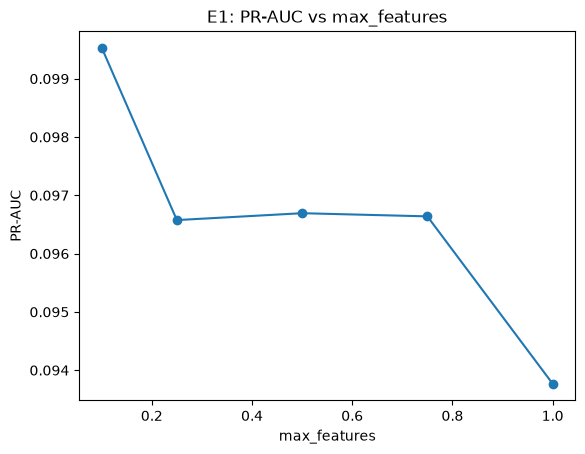

In [ ]:
# E4: Running Different Max_Features Inputs

max_feature_values = [0.1, 0.25, 0.5, 0.75, 1.0]

# empty table: one row for each max_features value
e1_resultsdf = pd.DataFrame(index=max_feature_values, columns=["ROC-AUC", "PR-AUC", "Processing Time (s)"])
e1_resultsdf.index.name = "max_features"

i = 0
while i < len(max_feature_values):
    mf = max_feature_values[i]

    # fit the model + score every transaction, timing both
    start = time.perf_counter() # start of measurements of model train time
    model = IsolationForest(max_features=mf, random_state=100)
    model.fit(newdf)
    scores = -model.score_samples(newdf) # calculate the anomaly score
    end = time.perf_counter() # end of measurements of model train time

    # add the results to the table
    e1_resultsdf.loc[mf, "ROC-AUC"] = roc_auc_score(df["isFraud"], scores)
    e1_resultsdf.loc[mf, "PR-AUC"] = average_precision_score(df["isFraud"], scores)
    e1_resultsdf.loc[mf, "Processing Time (s)"] = end - start

    # save this row to the results table
    all_results.loc[f"E1: max_features={mf}"] = e1_resultsdf.loc[mf]

    i += 1

e1_resultsdf = e1_resultsdf.astype(float) # converts all columns to  regular decimal numbers
display(e1_resultsdf.round(3))

# Line chart: PR-AUC vs max_features
e1_resultsdf["PR-AUC"].plot(kind="line", marker="o",
                            title="E1: PR-AUC vs max_features",
                            xlabel="max_features",
                            ylabel="PR-AUC")
plt.show()

### 2.6 E5 Feature Ablation — Transaction Amount Only


,ROC-AUC,PR-AUC,Processing Time (s)
E2: TransactionAmt only,0.608,0.048,6.617


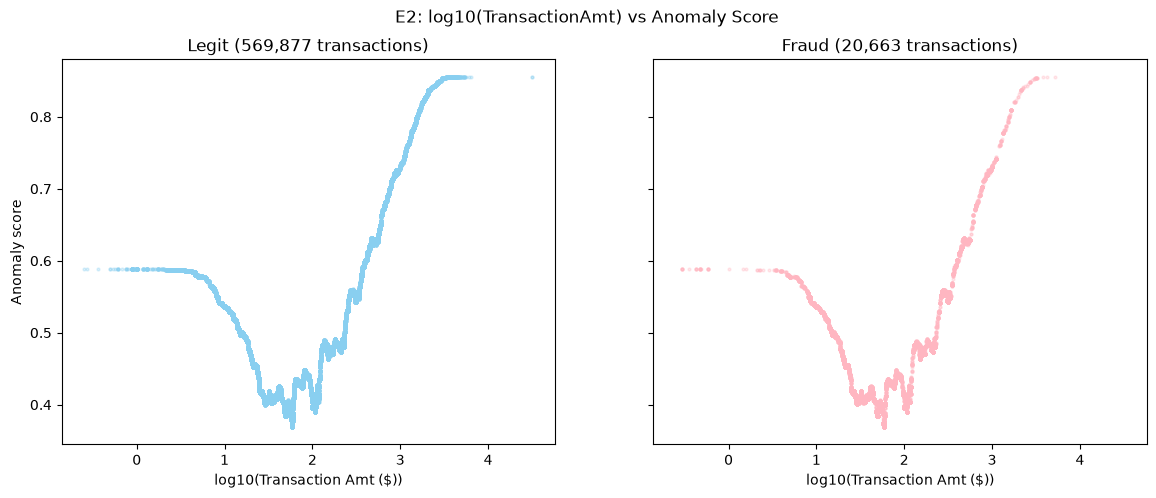

In [ ]:
# E5: only looking at TransactionAmt
start = time.perf_counter() #start of process time tracker
e2_model = IsolationForest(random_state=100)
e2_model.fit(newdf[["TransactionAmt"]])
e2_scores = -e2_model.score_samples(newdf[["TransactionAmt"]]) #anomaly score
end = time.perf_counter() #end of process time tracker

# save E2 results to the results table
all_results.loc["E2: TransactionAmt only"] = [roc_auc_score(df["isFraud"], e2_scores),
                                              average_precision_score(df["isFraud"], e2_scores),
                                              end - start]
display(all_results.loc[["E2: TransactionAmt only"]].round(3))

# table for the plot: log amount, anomaly score, fraud label
e2df = pd.DataFrame({
    "log_amt": np.log10(df["TransactionAmt"]),
    "anomaly_score": e2_scores,
    "isFraud": df["isFraud"],
})
e2_legit = e2df[e2df["isFraud"] == 0]
e2_fraud = e2df[e2df["isFraud"] == 1]

# Scatter: log10(amount) vs anomaly score, coloured by fraud
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

axes[0].scatter(e2_legit["log_amt"], e2_legit["anomaly_score"], s=4, alpha=0.3, color="#89CFF0")
axes[0].set_title(f"Legit ({len(e2_legit):,} transactions)")
axes[1].scatter(e2_fraud["log_amt"], e2_fraud["anomaly_score"], s=4, alpha=0.3, color="#FFB6C1")
axes[1].set_title(f"Fraud ({len(e2_fraud):,} transactions)")

for ax in axes:
    ax.set_xlabel("log10(Transaction Amt ($))")
axes[0].set_ylabel("Anomaly score")

fig.suptitle("E2: log10(TransactionAmt) vs Anomaly Score")
plt.show() 

### 2.7 E6 Feature Ablation — Temporal Features Only (Diagnostic)


,ROC-AUC,PR-AUC,Processing Time (s)
E3: TransactionDT only,0.54,0.046,3.669


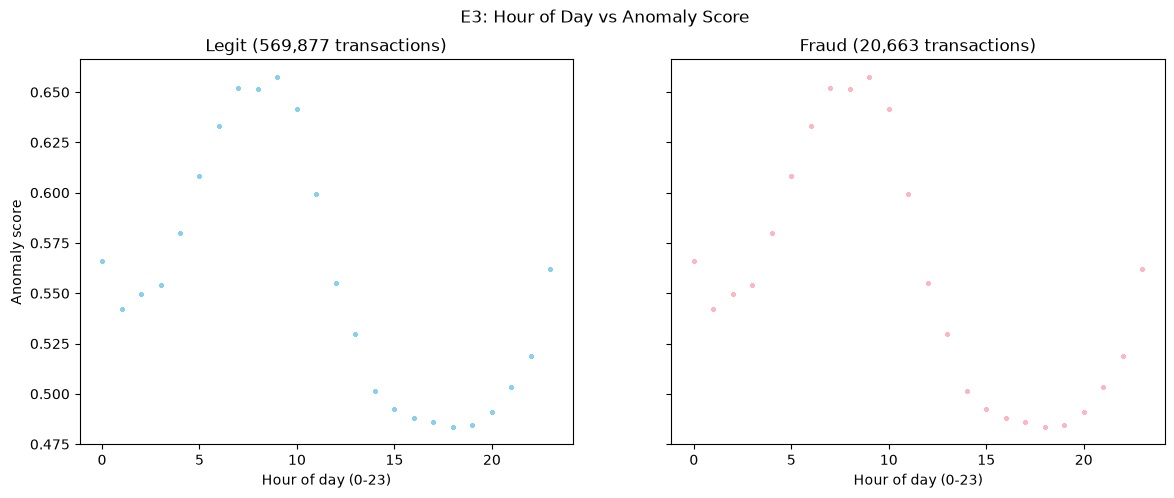

In [ ]:
# E6: Only looking at TransactionDT (Only flag transactions at unusual times)

# TransactionDT is in seconds -> convert to hour of day (0-23)
# kept in its own table so the original df doesn't change
e3df = pd.DataFrame({"hour": (df["TransactionDT"] // 3600) % 24}) # only considers within 24 hour

start = time.perf_counter() #start of process time tracker
e3_model = IsolationForest(random_state=100)
e3_model.fit(e3df)
e3_scores = -e3_model.score_samples(e3df) #anomaly score
end = time.perf_counter() #end of process time tracker

# save E2 results to the results table
all_results.loc["E3: TransactionDT only"] = [roc_auc_score(df["isFraud"], e3_scores),
                                              average_precision_score(df["isFraud"], e3_scores),
                                              end - start]
display(all_results.loc[["E3: TransactionDT only"]].round(3))

# table for the plot: hour of day, anomaly score, fraud label
e3_plotdf = pd.DataFrame({
    "hour": e3df["hour"],
    "anomaly_score": e3_scores,
    "isFraud": df["isFraud"],
})
e3_legit = e3_plotdf[e3_plotdf["isFraud"] == 0]
e3_fraud = e3_plotdf[e3_plotdf["isFraud"] == 1]

# Scatter: Hour of day vs anomaly score, coloured by fraud
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

axes[0].scatter(e3_legit["hour"], e3_legit["anomaly_score"], s=4, alpha=0.3, color="#89CFF0")
axes[0].set_title(f"Legit ({len(e3_legit):,} transactions)")
axes[1].scatter(e3_fraud["hour"], e3_fraud["anomaly_score"], s=4, alpha=0.3, color="#FFB6C1")
axes[1].set_title(f"Fraud ({len(e3_fraud):,} transactions)")

for ax in axes:
    ax.set_xlabel("Hour of day (0-23)")
axes[0].set_ylabel("Anomaly score")

fig.suptitle("E3: Hour of Day vs Anomaly Score")
plt.show()


### 2.8 E7 Feature Ablation — Card Features Only


,ROC-AUC,PR-AUC,Processing Time (s)
E4: Card only,0.656,0.07,6.795


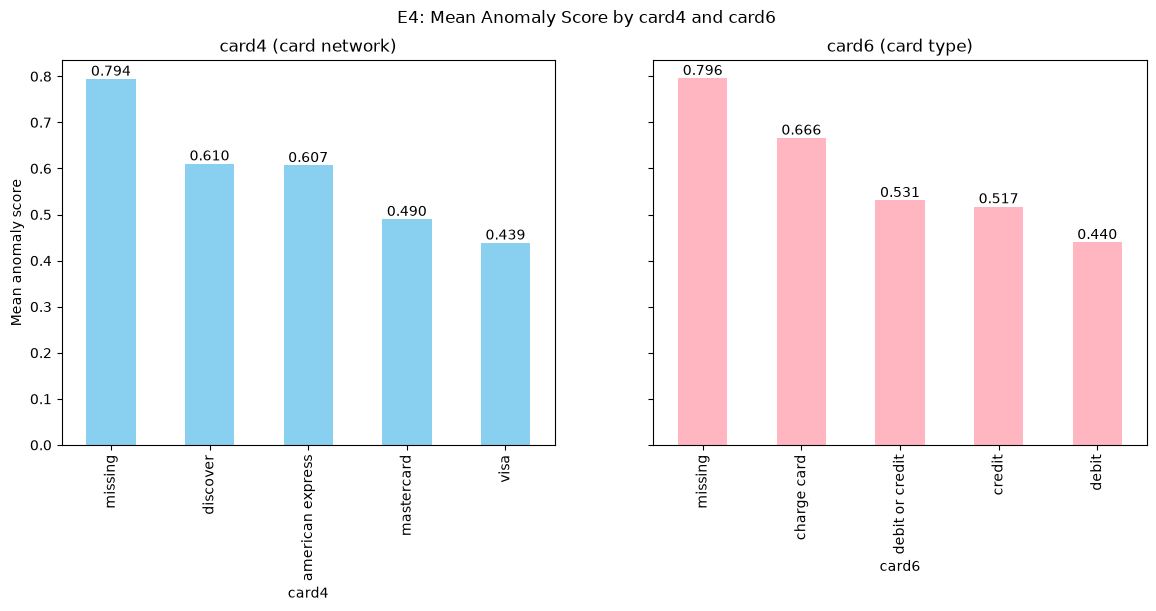

In [ ]:
# E7: Only looking at card card1-card3, card4-card6 (NOTE: card 4 and 6 are categorical)

# card4 (visa, mastercard, ...) and card6 (debit, credit, ...) are text -> convert each category to a number
# empty cells become their own "missing" category
card4_codes = df["card4"].fillna("missing").astype("category").cat.codes
card6_codes = df["card6"].fillna("missing").astype("category").cat.codes

# kept in its own table so the original df doesn't change
e4df = pd.DataFrame({
    "card1": newdf["card1"],
    "card2": newdf["card2"],
    "card3": newdf["card3"],
    "card4": card4_codes,
    "card5": newdf["card5"],
    "card6": card6_codes,
})

start = time.perf_counter() #start of process time tracker
e4_model = IsolationForest(random_state=100)
e4_model.fit(e4df)
e4_scores = -e4_model.score_samples(e4df) #anomaly score
end = time.perf_counter() #end of process time tracker

# save E4 results to the results table
all_results.loc["E4: Card only"] = [roc_auc_score(df["isFraud"], e4_scores),
                                    average_precision_score(df["isFraud"], e4_scores),
                                    end - start]
display(all_results.loc[["E4: Card only"]].round(3))


# table for the plot: card type (text), anomaly score, fraud label
e4_plotdf = pd.DataFrame({
    "card4": df["card4"].fillna("missing"),
    "card6": df["card6"].fillna("missing"),
    "anomaly_score": e4_scores,
    "isFraud": df["isFraud"],
})

# Bar chart: mean anomaly score by card4 and card6
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

card4_mean = e4_plotdf.groupby("card4")["anomaly_score"].mean().sort_values(ascending=False)
card4_bar = card4_mean.plot(kind="bar", ax=axes[0], color="#89CFF0",
                            title="card4 (card network)", xlabel="card4", ylabel="Mean anomaly score")
card4_bar.bar_label(card4_bar.containers[0], fmt="%.3f")

card6_mean = e4_plotdf.groupby("card6")["anomaly_score"].mean().sort_values(ascending=False)
card6_bar = card6_mean.plot(kind="bar", ax=axes[1], color="#FFB6C1",
                            title="card6 (card type)", xlabel="card6")
card6_bar.bar_label(card6_bar.containers[0], fmt="%.3f")

fig.suptitle("E4: Mean Anomaly Score by card4 and card6")
plt.show()
